# Bengali climate stance detection with XLM-R
Select a T4 GPU in Colab and run all cells. Upload `indic_climate_stage1_cleaned.zip` when prompted. This notebook trains simple and class-weighted XLM-R on Bengali. Labels are 0 = Against, 1 = Favour and 2 = None.

## 1. Install dependencies

In [ ]:
%pip -q install "transformers>=4.45,<5" sentencepiece safetensors

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2. Imports, seed, and GPU

In [ ]:
import os, json, random, zipfile, copy, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED=42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type=="cuda": print(torch.cuda.get_device_name(0))
else: print("Enable GPU: Runtime > Change runtime type > T4 GPU")

Device: cuda
Tesla T4


## 3. Upload and extract Stage 1 cleaned ZIP

In [ ]:
from google.colab import files
uploaded=files.upload()  # Upload indic_climate_stage1_cleaned.zip
zips=[n for n in uploaded if n.lower().endswith(".zip")]
if not zips: raise FileNotFoundError("Upload the Stage 1 cleaned ZIP.")
DATA_DIR=Path("/content/indic_climate_stage1_cleaned")
DATA_DIR.mkdir(exist_ok=True, parents=True)
with zipfile.ZipFile(zips[0]) as zf: zf.extractall(DATA_DIR)
print(sorted(p.name for p in DATA_DIR.glob("*.csv")))

Saving indic_climate_stage1_cleaned.zip to indic_climate_stage1_cleaned.zip
['bengali_test.csv', 'bengali_train.csv', 'bengali_val.csv', 'cross_language_integrity_check.csv', 'hindi_test.csv', 'hindi_train.csv', 'hindi_val.csv', 'label_distribution.csv', 'stage1_file_audit.csv']


## 4. Load Bengali splits

In [ ]:
def load_split(language, split):
    p=DATA_DIR/f"{language}_{split}.csv"
    if not p.exists(): raise FileNotFoundError(p)
    d=pd.read_csv(p)
    required={"example_id","split","language","original_text","text","label"}
    if not required.issubset(d.columns): raise ValueError(f"Missing columns: {required-set(d.columns)}")
    d=d.dropna(subset=["text","label"]).copy()
    d["text"]=d["text"].astype(str).str.strip()
    d["label"]=d["label"].astype(int)
    d=d[d.text.ne("")].reset_index(drop=True)
    if not set(d.label.unique()).issubset({0,1,2}): raise ValueError("Labels must be 0,1,2")
    return d

LANGUAGES = ("bengali",)
data = {lang: {s: load_split(lang, s) for s in ("train", "val", "test")} for lang in LANGUAGES}

## 5. Inspect distributions and calculate training weights

In [ ]:
LABEL_NAMES=["Against","Favour","None"]
def distribution(d,name):
    c=d.label.value_counts().reindex([0,1,2],fill_value=0)
    out=pd.DataFrame({"label":[0,1,2],"class":LABEL_NAMES,"count":c.values,
                      "percentage":(c.values/len(d)*100).round(2)})
    print(name); display(out); return out

weights = {}
for lang, splits in data.items():
    for split, frame in splits.items():
        distribution(frame, f"{lang.title()} {split}")
    weights[lang] = compute_class_weight("balanced", classes=np.arange(3), y=splits["train"].label)
    display(pd.Series(weights[lang], index=LABEL_NAMES, name=f"{lang.title()} training weights"))

Bengali train


,label,class,count,percentage
0,0,Against,308,10.73
1,1,Favour,2294,79.90
2,2,None,269,9.37


Bengali val


,label,class,count,percentage
0,0,Against,44,12.43
1,1,Favour,284,80.23
2,2,None,26,7.34


Bengali test


,label,class,count,percentage
0,0,Against,35,9.86
1,1,Favour,285,80.28
2,2,None,35,9.86


,Bengali training weights
Against,3.107143
Favour,0.417175
None,3.557621


## 6. Tokenizer and datasets

In [ ]:
MODEL_NAME="FacebookAI/xlm-roberta-base"
MAX_LENGTH=160
BATCH_SIZE=8  # Try 16 only if GPU memory allows
tokenizer=AutoTokenizer.from_pretrained(MODEL_NAME)
class StanceDataset(Dataset):
    def __init__(self,df):
        self.texts=df.text.astype(str).tolist()
        self.labels=df.label.astype(int).tolist()
    def __len__(self): return len(self.labels)
    def __getitem__(self,i):
        x=tokenizer(self.texts[i],truncation=True,max_length=MAX_LENGTH,
                    padding="max_length",return_tensors="pt")
        item={k:v.squeeze(0) for k,v in x.items()}
        item["labels"]=torch.tensor(self.labels[i],dtype=torch.long)
        return item

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

## 7. Training and evaluation
Both variants start with the same seed and settings. The weighted loss gives rarer training labels more influence. Each run keeps the epoch with the highest validation macro-F1.

In [ ]:
def evaluate(model,loader):
    model.eval(); ys=[]; ps=[]; total=0
    eval_loss=nn.CrossEntropyLoss()
    with torch.no_grad():
        for batch in loader:
            batch={k:v.to(device) for k,v in batch.items()}
            labels=batch.pop("labels")
            out=model(**batch)
            total+=eval_loss(out.logits,labels).item() * len(labels)
            ys.extend(labels.cpu().numpy()); ps.extend(out.logits.argmax(1).cpu().numpy())
    return {"loss":total/max(len(ys),1),"accuracy":accuracy_score(ys,ps),
            "macro_f1":f1_score(ys,ps,labels=[0,1,2],average="macro",zero_division=0),
            "labels":np.array(ys),"predictions":np.array(ps)}

def train_experiment(name, train_loader, val_loader, class_weights, epochs=3,lr=2e-5):
    set_seed()
    print(f"Training {name}")
    model=AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,num_labels=3,
        id2label={0:"Against",1:"Favour",2:"None"},
        label2id={"Against":0,"Favour":1,"None":2}).to(device)
    # Balanced weights have mean one over the training split. A fixed
    # denominator preserves their influence even in small, skewed batches.
    loss_fn=nn.CrossEntropyLoss(weight=class_weights, reduction="sum")
    optimizer=torch.optim.AdamW([
        {"params": model.base_model.parameters(), "lr": lr},
        {"params": model.classifier.parameters(), "lr": 3 * lr},
    ], weight_decay=0.01)
    steps=len(train_loader)*epochs
    scheduler=get_linear_schedule_with_warmup(optimizer,int(.1*steps),steps)
    best=(-1, float("-inf")); best_state=None; history=[]
    for epoch in range(epochs):
        model.train(); total=0
        for batch in train_loader:
            batch={k:v.to(device) for k,v in batch.items()}
            labels=batch.pop("labels")
            optimizer.zero_grad(set_to_none=True)
            logits=model(**batch).logits
            loss=loss_fn(logits,labels) / len(labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            optimizer.step(); scheduler.step()
            total+=loss.item()
        vm=evaluate(model,val_loader)
        row={"epoch":epoch+1,"train_loss":total/max(len(train_loader),1),
             "val_loss":vm["loss"],"val_accuracy":vm["accuracy"],"val_macro_f1":vm["macro_f1"]}
        history.append(row); print(row)
        rank = (vm["macro_f1"], -vm["loss"])
        if rank > best:
            best=rank; best_state={k: v.detach().to("cpu", copy=True) for k,v in model.state_dict().items()}
    if best_state is not None: model.load_state_dict(best_state)
    return model,pd.DataFrame(history)

In [ ]:
def export_predictions(model, loader, dataframe, experiment, split):

    model.eval()
    actual, predicted, probabilities = [], [], []

    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = batch.pop("labels")

            logits = model(**batch).logits
            probs = torch.softmax(logits, dim=1)

            actual.extend(labels.cpu().numpy())
            predicted.extend(logits.argmax(dim=1).cpu().numpy())
            probabilities.extend(probs.cpu().numpy())

    if len(dataframe) != len(actual):
        raise ValueError(
            f"Prediction count mismatch for {experiment}, {split}"
        )

    result = dataframe[
        ["example_id", "original_text", "text", "label"]
    ].copy().reset_index(drop=True)

    result.rename(columns={"label": "actual_label"}, inplace=True)

    result["predicted_label"] = predicted
    result["correct"] = (
        result["actual_label"] == result["predicted_label"]
    )

    probs = np.asarray(probabilities)

    result["prob_against"] = probs[:, 0]
    result["prob_favour"] = probs[:, 1]
    result["prob_none"] = probs[:, 2]

    result.insert(0, "experiment", experiment)
    result.insert(1, "split", split)

    return result

## 8. Run the two Bengali experiments

Training Bengali simple XLM-R


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{'epoch': 1, 'train_loss': 0.7489297323987345, 'val_loss': 0.6594477937383166, 'val_accuracy': 0.8022598870056498, 'val_macro_f1': 0.296760710553814}
{'epoch': 2, 'train_loss': 0.6299740393181698, 'val_loss': 0.685676869489042, 'val_accuracy': 0.8022598870056498, 'val_macro_f1': 0.296760710553814}
{'epoch': 3, 'train_loss': 0.572865733798998, 'val_loss': 0.5949526774765408, 'val_accuracy': 0.8022598870056498, 'val_macro_f1': 0.296760710553814}


,precision,recall,f1-score,support
Against,0.0000,0.0000,0.0000,35.0000
Favour,0.8028,1.0000,0.8906,285.0000
None,0.0000,0.0000,0.0000,35.0000
accuracy,0.8028,0.8028,0.8028,0.8028
macro avg,0.2676,0.3333,0.2969,355.0000
weighted avg,0.6445,0.8028,0.7150,355.0000


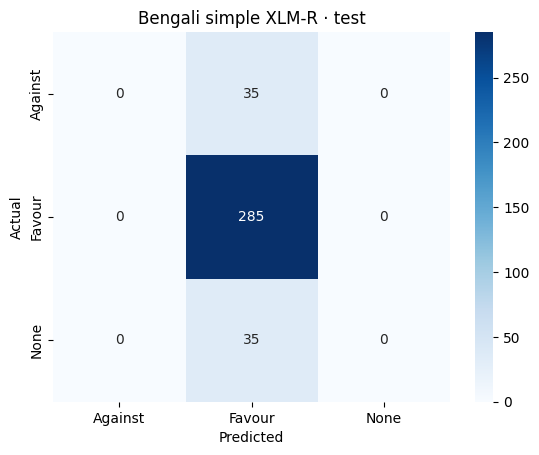

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Training Bengali weighted XLM-R
{'epoch': 1, 'train_loss': 1.1498480617667972, 'val_loss': 1.042118074530262, 'val_accuracy': 0.711864406779661, 'val_macro_f1': 0.3540981385900717}
{'epoch': 2, 'train_loss': 1.1113393328316032, 'val_loss': 0.6380111792330014, 'val_accuracy': 0.7909604519774012, 'val_macro_f1': 0.37521260550046537}
{'epoch': 3, 'train_loss': 1.0253970030705577, 'val_loss': 0.7008550985384796, 'val_accuracy': 0.711864406779661, 'val_macro_f1': 0.44456076901113545}


,precision,recall,f1-score,support
Against,0.2424,0.2286,0.2353,35.0000
Favour,0.8487,0.8070,0.8273,285.0000
None,0.2157,0.3143,0.2558,35.0000
accuracy,0.7014,0.7014,0.7014,0.7014
macro avg,0.4356,0.4500,0.4395,355.0000
weighted avg,0.7265,0.7014,0.7126,355.0000


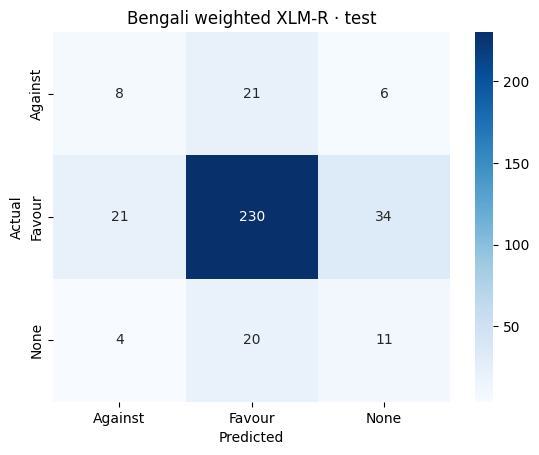

In [ ]:
EPOCHS = 3
LEARNING_RATE = 1e-5
OUT = Path("/content/xlmr_bengali")
results = []
for lang, splits in data.items():
    loaders = {s: DataLoader(StanceDataset(frame), batch_size=BATCH_SIZE, shuffle=(s == "train"))
               for s, frame in splits.items()}
    for variant in ("simple", "weighted"):
        run = OUT / "analysis" / lang / variant
        run.mkdir(parents=True, exist_ok=True)
        loss_weights = (torch.tensor(weights[lang], dtype=torch.float32, device=device)
                        if variant == "weighted" else None)
        model, history = train_experiment(f"{lang.title()} {variant} XLM-R", loaders["train"],
                                          loaders["val"], loss_weights, EPOCHS, LEARNING_RATE)
        history.to_csv(run / "history.csv", index=False)
        model_dir = OUT / "models" / lang / variant
        model.save_pretrained(model_dir)
        tokenizer.save_pretrained(model_dir)
        for split in ("val", "test"):
            pred = export_predictions(model, loaders[split], splits[split], variant, split)
            pred.to_csv(run / f"{split}_predictions.csv", index=False)
            actual, predicted = pred.actual_label, pred.predicted_label
            report = classification_report(actual, predicted, labels=[0, 1, 2],
                                           target_names=LABEL_NAMES, output_dict=True, zero_division=0)
            pd.DataFrame(report).T.to_csv(run / f"{split}_report.csv")
            cm = confusion_matrix(actual, predicted, labels=[0, 1, 2])
            matrix = pd.DataFrame(cm, index=LABEL_NAMES, columns=LABEL_NAMES)
            matrix.to_csv(run / f"{split}_confusion.csv")
            if split == "test":
                results.append({"language": lang.title(), "XLM-R": variant,
                                "best_epoch": int(history.sort_values(["val_macro_f1", "val_loss"], ascending=[False, True], kind="stable").iloc[0]["epoch"]),
                                "accuracy": accuracy_score(actual, predicted),
                                "macro_f1": report["macro avg"]["f1-score"]})
                display(pd.DataFrame(report).T.round(4))
                sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues")
                plt.title(f"{lang.title()} {variant} XLM-R · test")
                plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()
        del model
        if device.type == "cuda":
            torch.cuda.empty_cache()

## 9. Compare held-out test scores and download results
Macro-F1 gives each stance equal weight. A positive difference means weighting improved macro-F1 for Bengali.

In [ ]:
summary = pd.DataFrame(results)
display(summary.round(4))
comparison = summary.pivot(index="language", columns="XLM-R", values="macro_f1")
comparison["weighted minus simple"] = comparison["weighted"] - comparison["simple"]
display(comparison.round(4))
summary.to_csv(OUT / "analysis/test_scores.csv", index=False)
comparison.to_csv(OUT / "analysis/macro_f1_comparison.csv")
archive = shutil.make_archive(str(OUT / "xlmr_bengali_results"), "zip", OUT / "analysis")
files.download(archive)

,language,XLM-R,best_epoch,accuracy,macro_f1
0,Bengali,simple,3,0.8028,0.2969
1,Bengali,weighted,3,0.7014,0.4395


XLM-R,simple,weighted,weighted minus simple
language,,,
Bengali,0.2969,0.4395,0.1426


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>